## 01. 로딩·구조 확인

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = '서울특별시 강남구_쓰레기무단투기적발내역_20231231'

def find_project_paths():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == 'do_not_lung' and (p/'notebooks').is_dir():
            repo = p
            break
        if (p/'do_not_lung'/'notebooks').is_dir():
            repo = p/'do_not_lung'
            break
    else:
        raise FileNotFoundError('do_not_lung 프로젝트를 찾지 못했습니다.')
    return repo, repo.parent/'data'

REPO, DATA_ROOT = find_project_paths()
RAW_ROOT = DATA_ROOT/'raw_data'
OUT_DIR = DATA_ROOT/'processed_data'/DATASET_KEY
candidates = sorted(RAW_ROOT.rglob(DATASET_KEY+'*.csv'), key=lambda p: (p.name != DATASET_KEY+'.csv', str(p)))
if not candidates:
    raise FileNotFoundError(f'원본 CSV를 data/raw_data 아래에서 찾지 못했습니다: {DATASET_KEY}')
RAW_PATH = candidates[0]
for enc in ('utf-8-sig', 'cp949', 'euc-kr'):
    try:
        raw = pd.read_csv(RAW_PATH, encoding=enc, dtype='string', keep_default_na=False)
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError('CSV 인코딩 확인 실패')

expected = ['위반쓰레기','위반장소','위반일시']
if list(raw.columns) != expected:
    raise ValueError(f'원본 컬럼 구조가 예상과 다릅니다: {list(raw.columns)}')

raw_original = raw.copy(deep=True)
raw = raw.replace('', pd.NA)
print('원본:', RAW_PATH.name, '| 인코딩:', enc)
print('전체 구조:', raw.shape)
print('메모리 사용량(MiB):', round(raw.memory_usage(deep=True).sum()/1024**2, 3))
print('컬럼과 자료형:')
display(raw.dtypes.to_frame('dtype'))
print('샘플:')
display(raw.head(8))
print('전체 결측치:')
display(raw.isna().sum().to_frame('missing_count'))

원본: 서울특별시 강남구_쓰레기무단투기적발내역_20231231.csv | 인코딩: cp949
전체 구조: (28319, 3)
메모리 사용량(MiB): 6.222
컬럼과 자료형:


,dtype
위반쓰레기,string[python]
위반장소,string[python]
위반일시,string[python]


샘플:


,위반쓰레기,위반장소,위반일시
0,담배꽁초,대치동 선릉로424,2022-01-03 10:11
1,담배꽁초,대치동 테헤란로424,2022-01-03 10:34
2,담배꽁초,대치동 선릉로90길36,2022-01-03 10:40
3,담배꽁초,대치동 선릉로90길40,2022-01-03 10:50
4,담배꽁초,대치동 선릉로90길36,2022-01-03 11:08
5,담배꽁초,대치동 선릉로90길64,2022-01-03 11:33
6,담배꽁초,대치동 테헤란로510,2022-01-03 13:15
7,담배꽁초,논현동 39-1,2022-01-03 09:00


전체 결측치:


,missing_count
위반쓰레기,0
위반장소,0
위반일시,1


## 02. 데이터 품질·시간 오류 검토

In [2]:
clean = raw.copy(deep=True)
clean.insert(0, 'source_row_id', np.arange(1, len(clean)+1, dtype=np.int64))
for c in expected:
    clean[c] = clean[c].astype('string').replace('',pd.NA)  # 원본 문자열은 그대로 보존

parsed_dt = pd.to_datetime(clean['위반일시'], format='%Y-%m-%d %H:%M', errors='coerce')
clean['violation_datetime'] = parsed_dt.dt.strftime('%Y-%m-%d %H:%M').astype('string')
clean['datetime_valid_flag'] = parsed_dt.notna()
clean['recorded_year'] = parsed_dt.dt.year.astype('Int64')
clean['recorded_month'] = parsed_dt.dt.month.astype('Int64')
clean['recorded_day'] = parsed_dt.dt.day.astype('Int64')
clean['recorded_hour'] = parsed_dt.dt.hour.astype('Int64')
clean['recorded_weekday'] = parsed_dt.dt.dayofweek.astype('Int64')  # Monday=0
clean['year_month'] = parsed_dt.dt.strftime('%Y-%m').astype('string')
clean['is_weekend'] = parsed_dt.dt.dayofweek.ge(5).astype('boolean').where(parsed_dt.notna(), pd.NA)
clean['within_2022_2023_flag'] = parsed_dt.dt.year.between(2022, 2023).fillna(False)

# 원본 위반 유형은 관측된 범주일 뿐 흡연 노출 정답값이 아님
clean['cigarette_butt_offense_flag'] = clean['위반쓰레기'].eq('담배꽁초').fillna(False)
clean['duplicate_exact_record_flag'] = clean.duplicated(subset=expected, keep=False)
clean['duplicate_place_datetime_flag'] = (
    clean.duplicated(subset=['위반장소','위반일시'], keep=False)
    & clean[['위반장소','위반일시']].notna().all(axis=1)
)

# 장소명을 과하게 통합하지 않고 선행·후행 및 연속 공백만 표준화
clean['place_normalized'] = clean['위반장소'].str.replace(r'\s+', ' ', regex=True).str.strip()
clean['place_text_length'] = clean['place_normalized'].str.len().astype('Int64')

# 실제 장소 텍스트에 명시된 강남구 법정동명만 보수적으로 추출
LEGAL_DONG = [
    '압구정동','논현동','신사동','청담동','삼성동','대치동','역삼동',
    '도곡동','개포동','일원동','수서동','세곡동','자곡동','율현동'
]
raw_dong_pattern = re.compile(r'(?<![가-힣])([가-힣]+동)(?![가-힣])')

def extract_dong(text):
    if pd.isna(text):
        return (pd.NA, False, False)
    tokens = list(dict.fromkeys(raw_dong_pattern.findall(str(text))))
    found = [x for x in tokens if x in LEGAL_DONG]
    suspicious = any(x not in LEGAL_DONG for x in tokens)
    if len(found) == 1:
        return (found[0], False, suspicious)
    return (pd.NA, len(found) > 1, suspicious)

dong_values = clean['place_normalized'].map(extract_dong)
clean['extracted_legal_dong'] = pd.Series([x[0] for x in dong_values], dtype='string')
clean['multiple_dong_mention_flag'] = [bool(x[1]) for x in dong_values]
clean['unverified_dong_token_flag'] = [bool(x[2]) for x in dong_values]
clean['has_dong_text_flag'] = clean['extracted_legal_dong'].notna()

clean['has_station_exit_text_flag'] = clean['place_normalized'].str.contains(
    r'역\s*\d+\s*번\s*출구', regex=True, na=False
)
clean['has_road_number_text_flag'] = clean['place_normalized'].str.contains(
    r'(?:로|길)\s*\d+', regex=True, na=False
)
clean['has_building_text_flag'] = clean['place_normalized'].str.contains(
    r'빌딩|타워|센터|건물', regex=True, na=False
)
clean['has_explicit_coordinate_flag'] = False  # 원본에 좌표 컬럼 자체가 없음
clean['review_needed'] = (
    ~clean['datetime_valid_flag']
    | ~clean['within_2022_2023_flag']
    | clean['duplicate_exact_record_flag']
    | clean['multiple_dong_mention_flag']
    | clean['unverified_dong_token_flag']
    | clean['위반장소'].isna()
)

print('전체 행:',len(clean))
print('위반쓰레기별 건수:')
display(clean['위반쓰레기'].value_counts(dropna=False).to_frame('records'))
print('원본 완전 중복(추가 발생 행 수):', int(clean.duplicated(expected).sum()))
print('중복 포함 행 수:', int(clean['duplicate_exact_record_flag'].sum()))
print('동일 장소·시각 행 수:', int(clean['duplicate_place_datetime_flag'].sum()))
print('날짜 파싱 실패:', int((~clean['datetime_valid_flag']).sum()))
print('파싱 성공 중 2022~2023 이외:', int((clean['datetime_valid_flag'] & ~clean['within_2022_2023_flag']).sum()))
print('법정동 추출 가능:', int(clean['has_dong_text_flag'].sum()))
print('법정동 불확실 토큰:', int(clean['unverified_dong_token_flag'].sum()))
print('위경도 컬럼: 없음 / 좌표 합성하지 않음')
print('의심 일시 예시:')
display(clean.loc[~clean['datetime_valid_flag'], expected].head(12))
print('원본 연도 분포:')
display(clean['recorded_year'].value_counts(dropna=False).sort_index().to_frame('records'))

전체 행: 28319
위반쓰레기별 건수:


,records
위반쓰레기,
담배꽁초,21172
혼합배출,7147


원본 완전 중복(추가 발생 행 수): 1171
중복 포함 행 수: 2252
동일 장소·시각 행 수: 2252
날짜 파싱 실패: 103
파싱 성공 중 2022~2023 이외: 27
법정동 추출 가능: 23797
법정동 불확실 토큰: 10
위경도 컬럼: 없음 / 좌표 합성하지 않음
의심 일시 예시:


,위반쓰레기,위반장소,위반일시
1349,담배꽁초,대치동 테헤란로891,20220-12-71 12:10
1976,담배꽁초,강남역 1번출구,20220-21-11 10:65
2762,담배꽁초,역삼동 강남대로408,20220-30-41 25:02
2809,담배꽁초,삼성동 테헤란로81길10,0202-20-30 41:15
2849,담배꽁초,역삼동 선릉로91길8,20220-30-70 92:73
5326,담배꽁초,강남역 11번출구,0020-22-04 26:52
6298,담배꽁초,역삼동 강남대로102길11,<NA>
9499,담배꽁초,역삼동 테헤란로2길27,0000-20-22 08:03
9894,담배꽁초,논현동 도산대로128,2022-08-32 09:12
9895,담배꽁초,논현동 강남대로150길11,2022-08-33 09:27


원본 연도 분포:


,records
recorded_year,
2002,1
2021,26
2022,17798
2023,10391
<NA>,103


## 03. 기술통계·범주 분석

In [3]:
original_missing = clean[expected].isna().sum().to_frame('missing_count')
original_missing['missing_pct'] = clean[expected].isna().mean().mul(100).round(3)
print('컬럼별 결측률:')
display(original_missing)
print('위반장소 고유값:', clean['위반장소'].nunique(dropna=True))
print('기술통계:')
display(clean[['place_text_length','recorded_hour','recorded_weekday']].describe())

counts_type = clean['위반쓰레기'].value_counts(dropna=False)
counts_year = clean.groupby(['recorded_year','위반쓰레기'], dropna=False).size().rename('records').reset_index()
counts_month = clean.loc[clean['datetime_valid_flag']].groupby(['year_month','위반쓰레기'],dropna=False).size().rename('records').reset_index()
counts_hour = clean.loc[clean['datetime_valid_flag']].groupby(['recorded_hour','위반쓰레기'],dropna=False).size().rename('records').reset_index()
counts_weekday = clean.loc[clean['datetime_valid_flag']].groupby(['recorded_weekday','위반쓰레기'],dropna=False).size().rename('records').reset_index()
counts_dong = clean.groupby(['extracted_legal_dong','위반쓰레기'], dropna=False).size().rename('records').reset_index()
counts_place = clean['place_normalized'].value_counts(dropna=False)

print('연도×유형 분포:')
display(counts_year)
print('법정동×유형 상위:')
display(counts_dong.sort_values('records',ascending=False).head(20))
print('빈도 높은 위반장소:')
display(counts_place.head(20).to_frame('records'))
print('날짜·시간은 적발 시각이지 실제 흡연 시작 시각이 아님')

컬럼별 결측률:


,missing_count,missing_pct
위반쓰레기,0,0.000
위반장소,0,0.000
위반일시,1,0.004


위반장소 고유값: 7555
기술통계:


,place_text_length,recorded_hour,recorded_weekday
count,28319.0,28216.0,28216.0
mean,12.684311,10.81468,1.985221
std,4.965286,1.502741,1.37972
min,3.0,1.0,0.0
25%,9.0,10.0,1.0
50%,11.0,11.0,2.0
75%,14.0,12.0,3.0
max,26.0,18.0,6.0


연도×유형 분포:


,recorded_year,위반쓰레기,records
0,2002,담배꽁초,1
1,2021,담배꽁초,20
2,2021,혼합배출,6
3,2022,담배꽁초,15077
4,2022,혼합배출,2721
5,2023,담배꽁초,5971
6,2023,혼합배출,4420
7,<NA>,담배꽁초,103


법정동×유형 상위:


,extracted_legal_dong,위반쓰레기,records
18,역삼동,담배꽁초,9423
27,<NA>,담배꽁초,4502
4,대치동,담배꽁초,2793
3,논현동,혼합배출,2017
8,삼성동,담배꽁초,1995
19,역삼동,혼합배출,1886
2,논현동,담배꽁초,1429
9,삼성동,혼합배출,708
5,대치동,혼합배출,661
14,신사동,담배꽁초,593


빈도 높은 위반장소:


,records
place_normalized,
강남역 11번출구,1907
역삼동 강남대로406,1646
강남역 1번출구,920
역삼동 강남대로408,585
역삼동 테헤란로2길27,331
역삼동 강남대로94길10,269
역삼동 GFC,206
강남역11번출구,204
역삼동 테헤란로123,179


날짜·시간은 적발 시각이지 실제 흡연 시작 시각이 아님


## 04. 시각화 — 장소·시간·유형

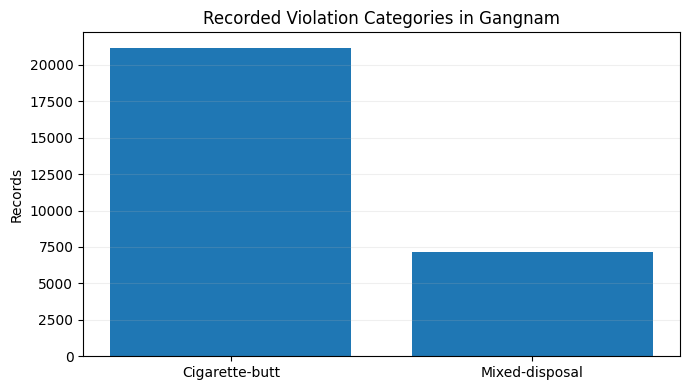

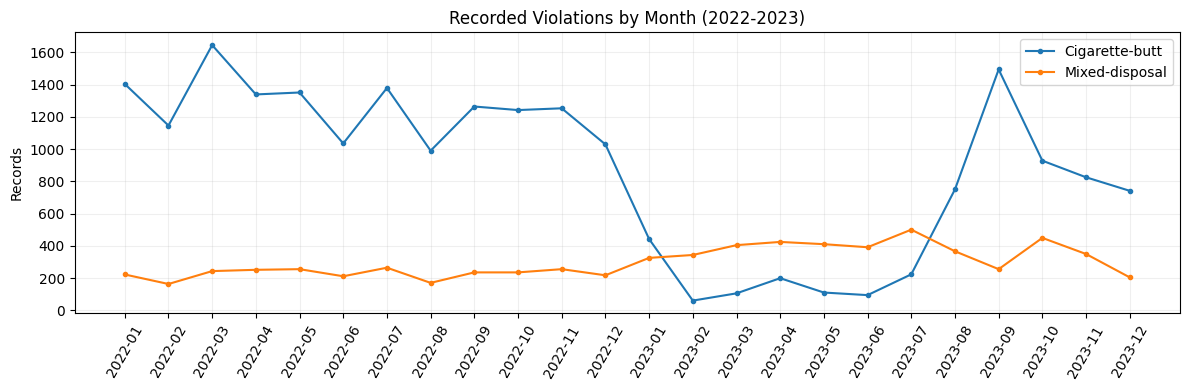

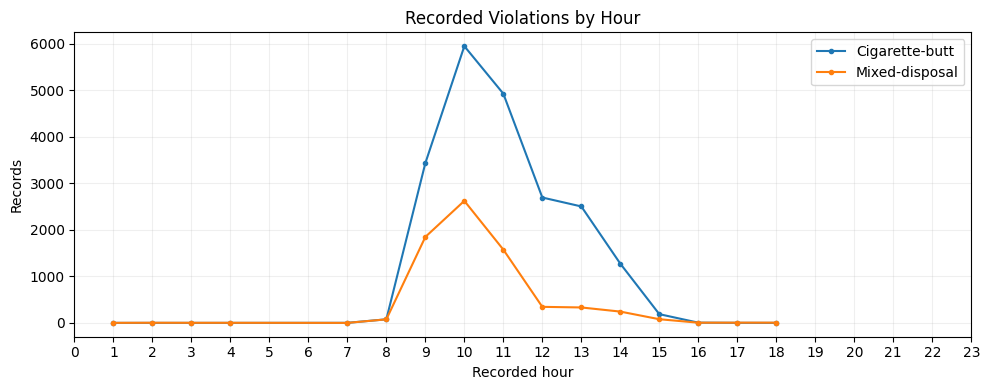

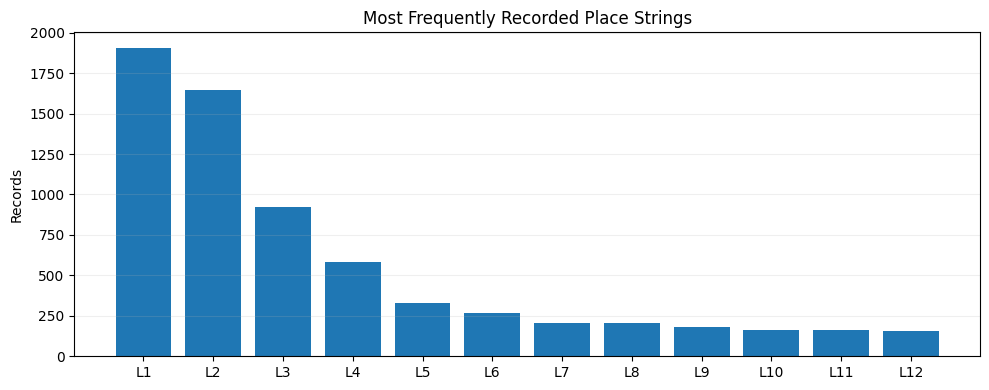

L1: 강남역 11번출구 (1,907건)
L2: 역삼동 강남대로406 (1,646건)
L3: 강남역 1번출구 (920건)
L4: 역삼동 강남대로408 (585건)
L5: 역삼동 테헤란로2길27 (331건)
L6: 역삼동 강남대로94길10 (269건)
L7: 역삼동 GFC (206건)
L8: 강남역11번출구 (204건)
L9: 역삼동 테헤란로123 (179건)
L10: 역삼동 테헤란로5길7 (162건)
L11: 논현동 강남대로128길4 (161건)
L12: 역삼동 한국빌딩 (159건)
좌표 컬럼이 없어 지리적 지도 및 링크 매핑은 수행하지 않음


In [4]:
plt.rcParams['axes.unicode_minus'] = False
# 한글 출력 폰트가 없는 실행 환경에서도 제목은 영문으로 그리며 원본 분류명은 표에서 확인
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['Cigarette-butt','Mixed-disposal'], [int(counts_type.get('담배꽁초',0)),int(counts_type.get('혼합배출',0))])
ax.set_title('Recorded Violation Categories in Gangnam')
ax.set_ylabel('Records')
ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show(); plt.close(fig)

# 2022~2023년 정상 파싱된 날짜만 월별 시각화
month_plot = counts_month.loc[counts_month['year_month'].str.startswith(('2022','2023'))].pivot_table(
    index='year_month', columns='위반쓰레기',values='records',aggfunc='sum',fill_value=0
).sort_index()
if not month_plot.empty:
    fig,ax=plt.subplots(figsize=(12,4))
    for col in month_plot.columns:
        label = 'Cigarette-butt' if col=='담배꽁초' else 'Mixed-disposal' if col=='혼합배출' else str(col)
        ax.plot(month_plot.index,month_plot[col],marker='.',label=label)
    ax.tick_params(axis='x',rotation=60)
    ax.set_ylabel('Records')
    ax.set_title('Recorded Violations by Month (2022-2023)')
    ax.grid(alpha=.2);ax.legend();plt.tight_layout();plt.show();plt.close(fig)

hour_plot = counts_hour.pivot_table(index='recorded_hour',columns='위반쓰레기',values='records',aggfunc='sum',fill_value=0).sort_index()
if not hour_plot.empty:
    fig,ax=plt.subplots(figsize=(10,4))
    for col in hour_plot.columns:
        label = 'Cigarette-butt' if col=='담배꽁초' else 'Mixed-disposal' if col=='혼합배출' else str(col)
        ax.plot(hour_plot.index,hour_plot[col],marker='o',markersize=3,label=label)
    ax.set_xlabel('Recorded hour')
    ax.set_ylabel('Records')
    ax.set_title('Recorded Violations by Hour')
    ax.set_xticks(range(24)); ax.grid(alpha=.2);ax.legend();plt.tight_layout();plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(10,4))
top=counts_place.head(12)
ax.bar(range(len(top)),top.values)
ax.set_xticks(range(len(top)));ax.set_xticklabels([f'L{i+1}' for i in range(len(top))])
ax.set_ylabel('Records');ax.set_title('Most Frequently Recorded Place Strings')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show();plt.close(fig)
for i,(place,num) in enumerate(top.items(),1): print(f'L{i}: {place} ({num:,}건)')
print('좌표 컬럼이 없어 지리적 지도 및 링크 매핑은 수행하지 않음')

## 05. 모델 입력변수 후보·집계

In [5]:
# 사건 기록 단위의 후보 X만 생성. 관측된 위반유형/담배꽁초 표시를 X에 넣지 않음.
# 장기 빈도/핫스팟 집계는 적발 강도 편향 및 학습-검증 누수를 유발할 수 있어 X에서 제외.
features = clean[[
    'source_row_id','place_normalized','extracted_legal_dong',
    'violation_datetime','recorded_year','recorded_month','recorded_day',
    'recorded_weekday','recorded_hour','is_weekend',
    'place_text_length','has_dong_text_flag',
    'has_station_exit_text_flag','has_road_number_text_flag',
    'has_building_text_flag','datetime_valid_flag',
    'within_2022_2023_flag','review_needed'
]].copy()

hour_num = pd.to_numeric(features['recorded_hour'],errors='coerce').to_numpy(dtype=float,na_value=np.nan)
features['hour_sin'] = np.sin(2*np.pi*hour_num/24)
features['hour_cos'] = np.cos(2*np.pi*hour_num/24)

stats=[]
def add(section,metric,category,value,unit='건'):
    stats.append({'section':section,'metric':metric,'category':category,'value':value,'unit':unit})

overall={
    'source_rows':len(raw),'source_columns':len(expected),'clean_rows':len(clean),
    'clean_columns':len(clean.columns),'feature_rows':len(features),
    'unique_places':clean['위반장소'].nunique(dropna=True),
    'extra_duplicate_rows':int(clean.duplicated(expected).sum()),
    'rows_in_duplicate_groups':int(clean['duplicate_exact_record_flag'].sum()),
    'duplicate_place_datetime_rows':int(clean['duplicate_place_datetime_flag'].sum()),
    'invalid_datetime_rows':int((~clean['datetime_valid_flag']).sum()),
    'valid_outside_2022_2023_rows':int((clean['datetime_valid_flag'] & ~clean['within_2022_2023_flag']).sum()),
    'extracted_dong_rows':int(clean['has_dong_text_flag'].sum()),
    'unverified_dong_token_rows':int(clean['unverified_dong_token_flag'].sum()),
    'review_needed_rows':int(clean['review_needed'].sum()),
    'geocoded_rows':0,
}
for k,v in overall.items(): add('overall',k,'',v,'열' if k.endswith('columns') else '건')
for k,v in counts_type.items(): add('violation_type','record_count',str(k),int(v))
for col in expected:
    add('missing','count',col,int(clean[col].isna().sum()))
    add('missing','percentage',col,round(100*float(clean[col].isna().mean()),5),'%')
for _,r in counts_year.iterrows():
    label='(날짜파싱실패)' if pd.isna(r['recorded_year']) else str(int(r['recorded_year']))
    add('year_violation_type','record_count',f"{label} | {r['위반쓰레기']}",int(r['records']))
for _,r in counts_month.iterrows():
    add('month_violation_type','record_count',f"{r['year_month']} | {r['위반쓰레기']}",int(r['records']))
for _,r in counts_hour.iterrows():
    add('hour_violation_type','record_count',f"{int(r['recorded_hour']):02d} | {r['위반쓰레기']}",int(r['records']))
for _,r in counts_weekday.iterrows():
    add('weekday_violation_type','record_count',f"{int(r['recorded_weekday'])} | {r['위반쓰레기']}",int(r['records']))
for _,r in counts_dong.iterrows():
    dong='(미추출)' if pd.isna(r['extracted_legal_dong']) else r['extracted_legal_dong']
    add('dong_violation_type','record_count',f"{dong} | {r['위반쓰레기']}",int(r['records']))
for place,count in counts_place.head(40).items():
    add('top_place','record_count',str(place),int(count))
for c in ['place_text_length','recorded_hour','recorded_weekday']:
    for metric in ['min','max','mean','median','std']:
        val=getattr(clean[c],metric)()
        add('numeric',metric,c, None if pd.isna(val) else float(val),'문자' if c=='place_text_length' else '값')
for item,count in clean.loc[~clean['datetime_valid_flag'],'위반일시'].value_counts(dropna=False).head(20).items():
    add('invalid_datetime_sample','record_count','(결측)' if pd.isna(item) else str(item),int(count))
summary = pd.DataFrame(stats, columns=['section','metric','category','value','unit'])
print('전처리 전:',raw.shape, '| clean.csv:',clean.shape, '| summary.csv:',summary.shape, '| features.csv:',features.shape)
print('features 샘플:')
display(features.head())

전처리 전: (28319, 3) | clean.csv: (28319, 28) | summary.csv: (226, 5) | features.csv: (28319, 20)
features 샘플:


,source_row_id,place_normalized,extracted_legal_dong,violation_datetime,recorded_year,recorded_month,recorded_day,recorded_weekday,recorded_hour,is_weekend,place_text_length,has_dong_text_flag,has_station_exit_text_flag,has_road_number_text_flag,has_building_text_flag,datetime_valid_flag,within_2022_2023_flag,review_needed,hour_sin,hour_cos
0,1,대치동 선릉로424,대치동,2022-01-03 10:11,2022,1,3,0,10,False,10,True,False,True,False,True,True,False,0.500000,-0.866025
1,2,대치동 테헤란로424,대치동,2022-01-03 10:34,2022,1,3,0,10,False,11,True,False,True,False,True,True,False,0.500000,-0.866025
2,3,대치동 선릉로90길36,대치동,2022-01-03 10:40,2022,1,3,0,10,False,12,True,False,True,False,True,True,False,0.500000,-0.866025
3,4,대치동 선릉로90길40,대치동,2022-01-03 10:50,2022,1,3,0,10,False,12,True,False,True,False,True,True,False,0.500000,-0.866025
4,5,대치동 선릉로90길36,대치동,2022-01-03 11:08,2022,1,3,0,11,False,12,True,False,True,False,True,True,False,0.258819,-0.965926


## 06. CSV 저장·재읽기·README 검증

In [6]:
OUT_DIR.mkdir(parents=True,exist_ok=True)
output_frames={'clean.csv':clean,'summary.csv':summary,'features.csv':features}
loaded={}
for fname,frame in output_frames.items():
    dest=OUT_DIR/fname
    frame.to_csv(dest,index=False,encoding='utf-8-sig')
    assert dest.read_bytes().startswith(b'\xef\xbb\xbf'),f'{fname} BOM 오류'
    reload=pd.read_csv(dest,encoding='utf-8-sig',dtype='string')
    assert reload.shape==frame.shape, f'{fname} 크기 불일치'
    assert list(reload.columns)==list(frame.columns),f'{fname} 컬럼 불일치'
    loaded[fname]=reload

for fname in ('clean.csv','features.csv'):
    assert loaded[fname]['source_row_id'].astype('Int64').tolist()==list(range(1,len(clean)+1))
for column in expected:
    original=clean[column].fillna('').astype('string').tolist()
    restored=loaded['clean.csv'][column].fillna('').astype('string').tolist()
    assert original==restored, f'{column} 원본 데이터 보존 실패'
assert loaded['clean.csv']['cigarette_butt_offense_flag'].eq('True').sum()==int(clean['cigarette_butt_offense_flag'].sum())
assert loaded['clean.csv']['datetime_valid_flag'].eq('True').sum()==int(clean['datetime_valid_flag'].sum())
for c in ['hour_sin','hour_cos']:
    before=features[c].to_numpy(dtype=float)
    after=pd.to_numeric(loaded['features.csv'][c],errors='coerce').to_numpy(dtype=float,na_value=np.nan)
    assert np.allclose(before,after,equal_nan=True,rtol=1e-12,atol=1e-12)

# README는 현재 실행에서 생성된 CSV의 실제 스키마로 구성
column_meanings={
    'source_row_id':'원본 CSV의 1부터 시작하는 데이터 행 번호(원본 순서 유지)',
    '위반쓰레기':'원본에 기록된 적발 쓰레기 유형(담배꽁초·혼합배출)',
    '위반장소':'원본에 기록된 장소 문자열(좌표가 아님)',
    '위반일시':'원본에 기록된 위반일시 문자열(수정하지 않음)',
    'violation_datetime':'엄격한 YYYY-MM-DD HH:MM 형식으로 파싱된 적발일시; 실패 시 결측',
    'datetime_valid_flag':'원본 위반일시를 날짜시간으로 파싱할 수 있는지',
    'recorded_year':'파싱된 적발연도',
    'recorded_month':'파싱된 적발월(1~12)',
    'recorded_day':'파싱된 적발일',
    'recorded_hour':'파싱된 적발 시각의 시(0~23)',
    'recorded_weekday':'파싱된 요일(월요일 0, 일요일 6)',
    'year_month':'파싱된 YYYY-MM',
    'is_weekend':'파싱된 일시가 토요일 또는 일요일인지(일시 오류는 결측)',
    'within_2022_2023_flag':'날짜가 2022~2023년 범위에 들어가는지(그 외는 오류 단정 아님)',
    'cigarette_butt_offense_flag':'위반쓰레기 원본값이 담배꽁초인지; 실제 간접흡연 노출 정답 아님',
    'duplicate_exact_record_flag':'위반쓰레기·위반장소·위반일시가 완전히 같은 다른 행의 존재 여부',
    'duplicate_place_datetime_flag':'장소·일시가 같은 다른 행의 존재 여부(위반유형 구분 안 함)',
    'place_normalized':'원본 위반장소 문자열의 앞뒤·연속 공백만 표준화',
    'place_text_length':'표준화 장소 문자열의 문자 길이',
    'extracted_legal_dong':'장소 문자열에 명시된 강남구 법정동명 추출 결과(추정·지오코딩 아님)',
    'multiple_dong_mention_flag':'서로 다른 확인된 법정동명이 둘 이상 추출됐는지',
    'unverified_dong_token_flag':'동으로 끝나는 문자열 중 허용 법정동명 이외 토큰이 있는지',
    'has_dong_text_flag':'장소 문자열에서 확인된 법정동명을 추출했는지',
    'has_station_exit_text_flag':'장소 문자열에 역·숫자·번출구 문구가 있는지',
    'has_road_number_text_flag':'장소 문자열에 로/길 뒤 숫자 표현이 있는지',
    'has_building_text_flag':'장소 문자열에 빌딩·타워·센터·건물 표현이 있는지',
    'has_explicit_coordinate_flag':'원본 위경도 컬럼 존재 여부(이 원본에는 없어 모두 False)',
    'review_needed':'날짜오류·범위 밖 연도·완전중복 등 검토 대상 플래그; 삭제 여부 아님',
    'hour_sin':'적발 시각(시)의 원형 사인 변환 sin(2π×시간/24)',
    'hour_cos':'적발 시각(시)의 원형 코사인 변환 cos(2π×시간/24)',
    'section':'EDA 통계의 구분',
    'metric':'EDA 통계 지표',
    'category':'집계 대상 또는 범주',
    'value':'실제 계산된 EDA 통계값',
    'unit':'통계값의 단위',
}
for fname,frame in output_frames.items():
    unknown=[c for c in frame.columns if c not in column_meanings]
    assert not unknown, f'컬럼 설명 누락: {fname}: {unknown}'

def escape_md(value):
    return str(value).replace('|','\\|').replace('\n',' ')

lines=[
    '# 강남구 쓰레기 무단투기 적발내역 — CSV 데이터 명세', '',
    f'- 원본 파일: `{RAW_PATH.name}` (읽기 전용)',
    f'- 원본 인코딩: `{enc}` / 출력 CSV: `utf-8-sig` / README: UTF-8',
    f'- 원본 크기: **{len(raw):,}행 × {len(expected)}열**',
    '- 분석 지역: 파일에 명시된 강남구(개별 행의 행정경계 검증 또는 주소 지오코딩 미실시)',
    '- 원본에는 위도·경도 및 행정동코드가 없음',
    '- 파일명 기준일: 2023-12-31 (실제 기록은 그 밖의 연도도 포함)',
    '', '## 전처리 및 데이터 품질', '',
    f'- 원본 유형: 담배꽁초 **{int(counts_type.get("담배꽁초",0)):,}건**, 혼합배출 **{int(counts_type.get("혼합배출",0)):,}건**',
    f'- 완전 동일 추가 중복 행: **{int(clean.duplicated(expected).sum()):,}건** / 관련 행: **{int(clean["duplicate_exact_record_flag"].sum()):,}건**',
    f'- 날짜 파싱 실패: **{int((~clean["datetime_valid_flag"]).sum()):,}건**; 원본 일시 보존, 자동 보정하지 않음',
    f'- 날짜 파싱 성공 중 2022~2023년 외 기록: **{int((clean["datetime_valid_flag"] & ~clean["within_2022_2023_flag"]).sum()):,}건**',
    '- 장소 텍스트는 공백만 표준화하고 상세 주소와 좌표를 임의로 부여하지 않음',
    '- 반복 적발이 실제로 발생했을 수 있으므로 중복 의심 행도 제거하지 않음',
    '', '## 결과 파일별 컬럼·자료형·의미·생성 방식', '',
]
file_purpose={
    'clean.csv':'원본 전 행·전 컬럼을 유지한 정제/검토 자료',
    'summary.csv':'유형·연도·월·시간·요일·법정동·장소별 집계 및 품질 통계',
    'features.csv':'원본 장소 문자열·기록 시각에서 직접 계산 가능한 모델 입력 후보(위반 유형 제외)',
}
for fname,frame in output_frames.items():
    lines += [f'### `{fname}`', '', f'- 용도: {file_purpose[fname]}', f'- 구조: **{len(frame):,}행 × {len(frame.columns)}열**', '', '| 컬럼명 | 자료형 | 생성 방식·의미 |','|---|---|---|']
    for col in frame.columns:
        lines.append(f'| `{escape_md(col)}` | `{frame[col].dtype}` | {escape_md(column_meanings[col])} |')
    lines.append('')
lines += [
    '## 파일 간 관계', '',
    '- `clean.csv`와 `features.csv`는 원본 기록 단위로 **1:1**이며 `source_row_id`로 연결한다.',
    '- `summary.csv`는 집계 단위가 여러 가지이므로 개별 사건과 직접 1:1 연결되지 않는다.',
    '- `clean.csv`에만 관측된 `위반쓰레기` 및 `cigarette_butt_offense_flag`를 보존한다. 이들은 실제 발생기록의 범주이지 간접흡연 노출 레이블이 아니다.',
    '', '## 사용 시 주의사항', '',
    '- **담배꽁초 적발 기록 ≠ 실제 흡연 발생 총량 ≠ 보행자 간접흡연 노출량**.',
    '- 단속인력의 배치, 단속 시간, 반복 단속, 장소명 기록 방식에 의한 **관측 편향**이 있을 수 있다.',
    '- 미적발 위치·시간은 0건이라고 관측된 것이 아니므로 부재(음성 클래스) 라벨을 만들지 않는다.',
    '- 적발 유형을 예측 대상으로 사용할 경우 `위반쓰레기`나 `cigarette_butt_offense_flag`는 **입력 X에서 제외**한다.',
    '- 장소별 전체 기간 빈도를 동일 기간 모델 X로 사용하면 **데이터 누수**가 생길 수 있어 features에서 제외했다.',
    '- 장소 문자열에서 법정동명만 보수적으로 추출한다. 역 출구 등 행정동을 알 수 없는 장소는 결측 유지한다.',
    '- 원본에 위·경도가 없어 도보 링크 또는 250m 격자와 직접 연결할 수 없다. 주소 정제·지오코딩은 별도 검증 후 필요하다.',
    '- 파생된 `recorded_hour`는 적발 시각이며 실제 흡연이 지속된 시점과 다를 수 있다.',
    '- 전처리 중 다른 데이터셋 병합, 좌표·250m 격자·도보 링크 생성, 정답 라벨 생성은 수행하지 않았다.',
]
README = OUT_DIR/'README.md'
README.write_text('\n'.join(lines)+'\n',encoding='utf-8')
read_back=README.read_text(encoding='utf-8')
for fname,frame in output_frames.items():
    for col in frame.columns:
        assert f'`{col}`' in read_back, f'README {fname} 컬럼 빠짐: {col}'
print('CSV 재읽기, 주요 값, 인코딩, README 컬럼 명세 검증 완료')
for fname in ['clean.csv','summary.csv','features.csv','README.md']:
    p=OUT_DIR/fname
    print(f'{fname}: {p.stat().st_size:,} bytes')

CSV 재읽기, 주요 값, 인코딩, README 컬럼 명세 검증 완료
clean.csv: 6,267,157 bytes
summary.csv: 13,537 bytes
features.csv: 4,486,238 bytes
README.md: 8,481 bytes
